# Materials Discovery Workshop - Google Colab Edition with Materials Project Integration

This interactive notebook demonstrates how machine learning can accelerate materials discovery by learning patterns from existing alloy compositions and generating new ones.

**New Feature**: Integration with the Materials Project database for real materials data!

**Workshop Goals:**
- Understand how variational autoencoders (VAEs) can model materials data
- Learn to generate new alloy compositions using ML
- Explore materials clustering and property analysis
- See how AI can accelerate materials R&D
- **NEW**: Use real materials data from Materials Project

**What you'll need:**
- Basic understanding of alloys and material properties
- Curiosity about how ML can help with materials science

Let's get started!

## Recommended Run Order (Best Practice)

1. **Step 0 setup**: register/sign in to Materials Project, paste API key, accept safety terms.
2. **Install + imports**: run dependency and import cells.
3. **Choose data source** and keep `Materials Project (Real)` selected for live API data.
4. **Authenticate + download latest data** from Materials Project (falls back to mock only if API key/service is unavailable).
5. **Train synthesizability models** on the loaded dataset.
6. **Train VAE + generate materials**.
7. **Filter candidates** by confidence, safety, and cost efficiency.
8. **Export shortlist for NOME validation**.

Note on NOME: this notebook can pre-screen and export candidates for NOME workflows, but full NOME validation generally requires downstream experimental/measurement context.

In [27]:
# Install notebook dependencies first in the ACTIVE kernel (run once per fresh kernel)
import sys as _sys

# In Google Colab, requirements.txt is not on disk — fetch it from the repo first
if 'google.colab' in _sys.modules:
    import subprocess
    subprocess.run(
        ['wget', '-q', '-O', 'requirements.txt',
         'https://raw.githubusercontent.com/jmeyer1980/materials-discovery-workshop/main/requirements.txt'],
        check=True
    )
    print("✅ requirements.txt fetched from GitHub.")

%pip install -r requirements.txt ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [28]:
import os
import platform
import sys
from pathlib import Path

# ── Detect runtime environment ──────────────────────────────────────────────
IN_COLAB  = 'google.colab' in sys.modules
IN_DOCKER = os.environ.get('IN_DOCKER', '0') == '1'

workspace_dir        = Path.cwd().resolve()
active_python        = str(Path(sys.executable).resolve())
active_prefix        = str(Path(sys.prefix).resolve())
virtual_env          = os.environ.get('VIRTUAL_ENV', '')
conda_prefix         = os.environ.get('CONDA_PREFIX', '')
expected_venv_frag   = str((workspace_dir / '.venv').resolve())

def _looks_like_repo_venv(p: str) -> bool:
    return p.replace('\\', '/').lower().startswith(
        expected_venv_frag.replace('\\', '/').lower()
    )

using_repo_venv = any(
    _looks_like_repo_venv(c)
    for c in [active_python, active_prefix, virtual_env]
    if c
)

print('=== PYTHON ENVIRONMENT CHECK ===')
print(f'Python executable : {active_python}')
print(f'Python version    : {platform.python_version()}')
print(f'Working directory : {workspace_dir}')
print(f'requirements.txt  : {"present" if (workspace_dir / "requirements.txt").exists() else "NOT FOUND"}')
print()

if IN_COLAB:
    print('✅ Running in Google Colab — managed runtime, no local .venv needed.')
    print('   Packages were installed via %pip in the previous cell.')
elif IN_DOCKER:
    print('✅ Running inside Docker container — all dependencies are baked into the image.')
    print('   Connected to Colab via local runtime on port 8888.')
elif using_repo_venv:
    print('✅ Running on the project .venv (local VS Code / Jupyter).')
else:
    print('ℹ️  Not running on the project .venv — this is normal for:')
    print('   • Google Colab hosted runtime')
    print('   • JupyterHub / Binder / any managed kernel')
    print('   • Docker local runtime (set IN_DOCKER=1 in docker-compose)')
    print('   Packages installed via %pip go into the active kernel regardless.')


=== PYTHON ENVIRONMENT CHECK ===
Python executable : C:\Users\jerio\OneDrive\Desktop\MaterialComparison\venv\Scripts\python.exe
Python version    : 3.12.10
Working directory : C:\Users\jerio\OneDrive\Desktop\MaterialComparison
requirements.txt  : present

ℹ️  Not running on the project .venv — this is normal for:
   • Google Colab hosted runtime
   • JupyterHub / Binder / any managed kernel
   • Docker local runtime (set IN_DOCKER=1 in docker-compose)
   Packages installed via %pip go into the active kernel regardless.


In [29]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import random
from typing import List, Tuple
import ipywidgets as widgets
from IPython.display import display
from scipy.stats import ks_2samp
import requests
import time

_workshop_bootstrap_symbols = (pd, np, KMeans, PCA, StandardScaler, silhouette_score, Dataset, DataLoader, List, Tuple, widgets, display, ks_2samp, requests, time)
print(f"Loaded {len(_workshop_bootstrap_symbols)} workshop helper symbols")
# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

print("✅ Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Running on: {'GPU' if torch.cuda.is_available() else 'CPU'}")

Loaded 15 workshop helper symbols
✅ Libraries imported successfully!
PyTorch version: 2.10.0+cpu
Running on: CPU


## Step 0: Materials Project Registration, API Key, and Safety Acceptance

Before running the workshop, complete the setup below:

1. Register for a Materials Project account: https://materialsproject.org/dashboard
2. Create and copy your API key from your account settings.
3. Enter your API key in the next cell.
4. Expand the agreement, review it, and confirm acceptance.

In [ ]:
from IPython.display import display, Markdown
import os

MP_SIGNUP_URL = "https://materialsproject.org/dashboard"
materials_project_api_key = globals().get("materials_project_api_key", os.getenv("MP_API_KEY", ""))
terms_accepted = bool(globals().get("terms_accepted", False))
workshop_ready = bool(globals().get("workshop_ready", False))

display(Markdown(f"🔗 Register / sign in: [{MP_SIGNUP_URL}]({MP_SIGNUP_URL})"))

def assert_workshop_prereqs(require_api_key: bool = False):
    if not bool(globals().get("workshop_ready", False)):
        raise RuntimeError(
            "Please complete Step 0 first: accept safety/terms and confirm setup. "
            "If widgets are blank, run: terms_accepted=True; workshop_ready=True"
        )
    if require_api_key and not str(globals().get("materials_project_api_key", "")).strip():
        raise RuntimeError(
            "Materials Project API key is required for real-data mode."
        )

print("\nStep 0 setup:")
print("- If widgets render below, use them and click 'Confirm Setup'.")
print("- If widgets do NOT render in VS Code, run this in a new cell:")
print("  materials_project_api_key = 'YOUR_API_KEY'  # or '' for synthetic mode")
print("  terms_accepted = True")
print("  workshop_ready = True")

try:
    import ipywidgets as widgets

    api_key_input = widgets.Password(
        value=str(materials_project_api_key),
        description="MP API Key:",
        placeholder="Paste your Materials Project API key",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="70%")
    )

    agreement_text = widgets.HTML(
        value="""
        <h4>⚠️ Safety & Terms Agreement</h4>
        <ul>
          <li>This notebook generates candidate materials for research guidance only.</li>
          <li>Predictions are not guaranteed and must be validated experimentally.</li>
          <li>You are responsible for hazard review, PPE selection, and institutional compliance.</li>
          <li>Do not synthesize materials without proper supervision and safety controls.</li>
        </ul>
        """
    )

    agreement_panel = widgets.Accordion(children=[agreement_text])
    agreement_panel.set_title(0, "Expand to read Safety & Terms")

    accept_checkbox = widgets.Checkbox(
        value=terms_accepted,
        description="I accept the safety and terms agreement",
        indent=False
    )

    confirm_button = widgets.Button(
        description="Confirm Setup",
        button_style="success",
        icon="check"
    )

    setup_status = widgets.Output()

    def confirm_setup(_):
        global materials_project_api_key, terms_accepted, workshop_ready
        materials_project_api_key = api_key_input.value.strip()
        terms_accepted = bool(accept_checkbox.value)
        workshop_ready = terms_accepted

        with setup_status:
            setup_status.clear_output()
            if not terms_accepted:
                print("❌ Please accept the safety and terms agreement to continue.")
                return
            if materials_project_api_key:
                print("✅ Setup confirmed. API key saved for this notebook session.")
            else:
                print("✅ Agreement accepted. API key left blank (synthetic mode).")
            print("➡️ You can now run the next cell.")

    confirm_button.on_click(confirm_setup)

    display(widgets.VBox([api_key_input, agreement_panel, accept_checkbox, confirm_button, setup_status]))
    print("\nIf the controls above are blank, use the manual fallback commands shown above.")

except Exception as widget_error:
    print(f"\nWidget UI unavailable: {widget_error}")
    display(Markdown("""
### Safety & Terms (manual mode)
- This notebook generates candidate materials for research guidance only.
- Predictions are not guaranteed and must be validated experimentally.
- You are responsible for hazard review, PPE selection, and institutional compliance.
- Do not synthesize materials without proper supervision and safety controls.
"""))

🔗 Register / sign in: [https://materialsproject.org/dashboard](https://materialsproject.org/dashboard)


Step 0 setup:
- If widgets render below, use them and click 'Confirm Setup'.
- If widgets do NOT render in VS Code, run this in a new cell:
  materials_project_api_key = 'YOUR_API_KEY'  # or '' for synthetic mode
  terms_accepted = True
  workshop_ready = True



If the controls above are blank, use the manual fallback commands shown above.


In [31]:
# Synthesizability Prediction Module for Materials Discovery Workshop
# This code is embedded directly in the notebook for Colab compatibility

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from typing import Dict, List, Tuple, Optional, Union
import warnings
warnings.filterwarnings('ignore')
_typing_type_markers: Tuple[Optional[float], Union[int, float]] = (None, 0.0)

# Mock ICSD data for demonstration (in practice, this would come from actual ICSD database)
def generate_mock_icsd_data(n_samples: int = 1000) -> pd.DataFrame:
    """Generate mock ICSD data representing experimentally synthesized materials."""
    np.random.seed(42)
    
    data = []
    for i in range(n_samples):
        formation_energy = np.random.normal(-2.0, 1.5)
        formation_energy = np.clip(formation_energy, -8, 2)
        
        band_gap = np.random.exponential(1.0)
        band_gap = np.clip(band_gap, 0, 8)
        
        energy_above_hull = np.random.exponential(0.05)
        energy_above_hull = np.clip(energy_above_hull, 0, 0.5)
        
        electronegativity = np.random.normal(1.8, 0.5)
        electronegativity = np.clip(electronegativity, 0.7, 2.5)
        
        atomic_radius = np.random.normal(1.4, 0.3)
        atomic_radius = np.clip(atomic_radius, 0.8, 2.2)
        
        nsites = np.random.randint(1, 20)
        density = np.random.normal(6.0, 3.0)
        density = np.clip(density, 2, 25)
        
        data.append({
            'formation_energy_per_atom': formation_energy,
            'band_gap': band_gap,
            'energy_above_hull': energy_above_hull,
            'electronegativity': electronegativity,
            'atomic_radius': atomic_radius,
            'nsites': nsites,
            'density': density,
            'synthesizable': 1
        })
    
    return pd.DataFrame(data)

def generate_mock_mp_only_data(n_samples: int = 1000) -> pd.DataFrame:
    """Generate mock MP-only data representing theoretically predicted materials."""
    np.random.seed(123)
    
    data = []
    for i in range(n_samples):
        formation_energy = np.random.normal(-0.5, 2.0)
        formation_energy = np.clip(formation_energy, -8, 4)
        
        band_gap = np.random.exponential(2.0)
        band_gap = np.clip(band_gap, 0, 12)
        
        energy_above_hull = np.random.exponential(0.2)
        energy_above_hull = np.clip(energy_above_hull, 0, 1.0)
        
        electronegativity = np.random.normal(1.6, 0.8)
        electronegativity = np.clip(electronegativity, 0.5, 3.0)
        
        atomic_radius = np.random.normal(1.5, 0.5)
        atomic_radius = np.clip(atomic_radius, 0.6, 2.8)
        
        nsites = np.random.randint(1, 50)
        density = np.random.normal(8.0, 4.0)
        density = np.clip(density, 1, 30)
        
        data.append({
            'formation_energy_per_atom': formation_energy,
            'band_gap': band_gap,
            'energy_above_hull': energy_above_hull,
            'electronegativity': electronegativity,
            'atomic_radius': atomic_radius,
            'nsites': nsites,
            'density': density,
            'synthesizable': 0
        })
    
    return pd.DataFrame(data)

def _get_api_training_data(n_samples: int = 1500) -> pd.DataFrame:
    """Fetch real Materials Project data and construct synthesizability labels."""
    api_key = str(globals().get('materials_project_api_key', '')).strip()
    if not api_key:
        raise ValueError('No Materials Project API key found in notebook session.')

    from materials_discovery_api import get_training_dataset

    target_n = max(int(n_samples), 400)
    ml_features, _ = get_training_dataset(
        api_key=api_key,
        n_materials=target_n,
        energy_above_hull_max=0.5
    )

    if ml_features.empty:
        raise ValueError('Materials Project returned an empty training dataset.')

    required = [
        'formation_energy_per_atom', 'band_gap', 'energy_above_hull',
        'electronegativity', 'atomic_radius', 'density'
    ]
    for col in required:
        if col not in ml_features.columns:
            raise ValueError(f'Missing required API feature column: {col}')

    api_df = ml_features.copy()
    if 'nsites' not in api_df.columns:
        api_df['nsites'] = 8

    # Proxy labels for classifier training: stable ~ synthesizable positive class
    api_df['synthesizable'] = (api_df['energy_above_hull'] <= 0.10).astype(int)
    api_df = api_df.dropna(subset=['formation_energy_per_atom', 'band_gap', 'energy_above_hull', 'electronegativity', 'atomic_radius', 'nsites', 'density'])

    # Keep both classes; if one class is missing, fail and let caller fallback to mock.
    class_counts = api_df['synthesizable'].value_counts().to_dict()
    if class_counts.get(0, 0) == 0 or class_counts.get(1, 0) == 0:
        raise ValueError(f'API training data is not class-balanced enough: {class_counts}')

    return api_df

def generate_authenticated_icsd_data(n_samples: int = 1000) -> pd.DataFrame:
    """Generate positive-class data from authenticated Materials Project API."""
    print("🔐 Generating authenticated ICSD-like data from Materials Project API...")
    try:
        api_df = _get_api_training_data(max(n_samples * 2, 400))
        pos_df = api_df[api_df['synthesizable'] == 1].copy()
        if len(pos_df) == 0:
            raise ValueError('No positive-class data from API.')
        return pos_df.sample(n=min(n_samples, len(pos_df)), random_state=42, replace=False).reset_index(drop=True)
    except Exception as exc:
        print(f"⚠️ Authenticated ICSD path unavailable ({exc}); falling back to mock ICSD data.")
        return generate_mock_icsd_data(n_samples)

def generate_authenticated_mp_only_data(n_samples: int = 1000) -> pd.DataFrame:
    """Generate negative-class data from authenticated Materials Project API."""
    print("🔐 Generating authenticated MP-only-like data from Materials Project API...")
    try:
        api_df = _get_api_training_data(max(n_samples * 2, 400))
        neg_df = api_df[api_df['synthesizable'] == 0].copy()
        if len(neg_df) == 0:
            raise ValueError('No negative-class data from API.')
        return neg_df.sample(n=min(n_samples, len(neg_df)), random_state=123, replace=False).reset_index(drop=True)
    except Exception as exc:
        print(f"⚠️ Authenticated MP-only path unavailable ({exc}); falling back to mock MP-only data.")
        return generate_mock_mp_only_data(n_samples)

class SynthesizabilityClassifier:
    """ML-based classifier for predicting material synthesizability."""
    
    def __init__(self, model_type: str = 'random_forest'):
        self.model_type = model_type
        self.model = None
        self.scaler = StandardScaler()
        self.feature_columns = [
            'formation_energy_per_atom', 'band_gap', 'energy_above_hull',
            'electronegativity', 'atomic_radius', 'nsites', 'density'
        ]
        self.is_trained = False
    
    def prepare_training_data(self) -> Tuple[pd.DataFrame, pd.Series]:
        """Prepare training data, preferring authenticated API-backed data when available."""
        use_api = bool(str(globals().get('materials_project_api_key', '')).strip())

        if use_api:
            print('🔄 Preparing synthesizability training data from Materials Project API...')
            icsd_data = generate_authenticated_icsd_data(1500)
            mp_only_data = generate_authenticated_mp_only_data(1500)
        else:
            print('ℹ️ No API key detected for classifier training; using mock training data.')
            icsd_data = generate_mock_icsd_data(1500)
            mp_only_data = generate_mock_mp_only_data(1500)

        training_data = pd.concat([icsd_data, mp_only_data], ignore_index=True)
        training_data = training_data.sample(frac=1, random_state=42).reset_index(drop=True)

        # Ensure required columns exist and are numeric
        for col in self.feature_columns + ['synthesizable']:
            if col not in training_data.columns:
                raise ValueError(f'Missing required training column: {col}')
            training_data[col] = pd.to_numeric(training_data[col], errors='coerce')

        training_data = training_data.dropna(subset=self.feature_columns + ['synthesizable'])

        X = training_data[self.feature_columns]
        y = training_data['synthesizable'].astype(int)

        if y.nunique() < 2:
            raise ValueError('Training target has a single class after preprocessing.')

        return X, y
    
    def train(self, test_size: float = 0.2):
        """Train the synthesizability classifier."""
        X, y = self.prepare_training_data()
        
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42, stratify=y
        )
        
        X_train_scaled = self.scaler.fit_transform(X_train)
        X_test_scaled = self.scaler.transform(X_test)
        
        if self.model_type == 'random_forest':
            self.model = RandomForestClassifier(
                n_estimators=200, max_depth=10, min_samples_split=5,
                min_samples_leaf=2, random_state=42, n_jobs=-1
            )
        elif self.model_type == 'gradient_boosting':
            self.model = GradientBoostingClassifier(
                n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42
            )
        else:
            raise ValueError(f"Unsupported model type: {self.model_type}")
        
        self.model.fit(X_train_scaled, y_train)
        
        y_pred = self.model.predict(X_test_scaled)
        y_pred_proba = self.model.predict_proba(X_test_scaled)[:, 1]
        
        metrics = {
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred),
            'f1_score': f1_score(y_test, y_pred),
            'mean_predicted_probability': float(np.mean(y_pred_proba))
        }
        
        cv_scores = cross_val_score(self.model, self.scaler.transform(X), y, cv=5)
        metrics['cv_mean'] = cv_scores.mean()
        metrics['cv_std'] = cv_scores.std()
        
        self.is_trained = True
        
        return metrics
    
    def predict(self, materials_df: pd.DataFrame) -> pd.DataFrame:
        """Predict synthesizability for new materials."""
        if not self.is_trained:
            raise ValueError("Model must be trained before making predictions")
        
        X_pred = materials_df[self.feature_columns].copy()
        X_pred = X_pred.fillna(X_pred.mean())
        X_pred_scaled = self.scaler.transform(X_pred)
        
        predictions = self.model.predict(X_pred_scaled)
        probabilities = self.model.predict_proba(X_pred_scaled)[:, 1]
        
        results_df = materials_df.copy()
        results_df['synthesizability_prediction'] = predictions
        results_df['synthesizability_probability'] = probabilities
        results_df['synthesizability_confidence'] = np.abs(probabilities - 0.5) * 2
        
        return results_df
    
    def predict_single(self, material_properties: Dict) -> Dict:
        """Predict synthesizability for a single material."""
        df = pd.DataFrame([material_properties])
        result_df = self.predict(df)
        
        return {
            'prediction': int(result_df['synthesizability_prediction'].iloc[0]),
            'probability': float(result_df['synthesizability_probability'].iloc[0]),
            'confidence': float(result_df['synthesizability_confidence'].iloc[0])
        }

class LLMSynthesizabilityPredictor:
    """LLM-based synthesizability predictor using rule-based heuristics."""
    
    def __init__(self):
        self.rules = {
            'thermodynamic_stability': {
                'energy_above_hull_threshold': 0.1,
                'formation_energy_min': -4.0,
                'formation_energy_max': 1.0
            },
            'structural_complexity': {
                'nsites_max': 20,
                'density_min': 2.0,
                'density_max': 25.0
            },
            'electronic_properties': {
                'band_gap_max': 8.0
            },
            'elemental_properties': {
                'electronegativity_min': 0.7,
                'electronegativity_max': 2.8,
                'atomic_radius_min': 0.8,
                'atomic_radius_max': 2.5
            }
        }
    
    def predict_synthesizability(self, material_data: Dict) -> Dict:
        """Predict synthesizability using rule-based system."""
        score = 0.0
        max_score = 10.0
        reasons = []
        
        e_hull = material_data.get('energy_above_hull', 0)
        if e_hull <= self.rules['thermodynamic_stability']['energy_above_hull_threshold']:
            score += 2.0
            reasons.append(f"Low energy above hull ({e_hull:.3f} eV/atom) indicates stability")
        else:
            reasons.append(f"High energy above hull ({e_hull:.3f} eV/atom) indicates instability")
        
        formation_energy = material_data.get('formation_energy_per_atom', 0)
        if (self.rules['thermodynamic_stability']['formation_energy_min'] <= 
            formation_energy <= self.rules['thermodynamic_stability']['formation_energy_max']):
            score += 1.5
            reasons.append(f"Formation energy ({formation_energy:.3f} eV/atom) is reasonable")
        else:
            reasons.append(f"Formation energy ({formation_energy:.3f} eV/atom) is extreme")
        
        nsites = material_data.get('nsites', 10)
        if nsites <= self.rules['structural_complexity']['nsites_max']:
            score += 1.0
            reasons.append(f"Unit cell size ({nsites} sites) is reasonable")
        else:
            reasons.append(f"Unit cell size ({nsites} sites) is very large")
        
        density = material_data.get('density', 5.0)
        if (self.rules['structural_complexity']['density_min'] <= density <= 
            self.rules['structural_complexity']['density_max']):
            score += 1.0
            reasons.append(f"Density ({density:.1f} g/cm³) is reasonable")
        else:
            reasons.append(f"Density ({density:.1f} g/cm³) is unusual")
        
        band_gap = material_data.get('band_gap', 0)
        if band_gap <= self.rules['electronic_properties']['band_gap_max']:
            score += 1.5
            reasons.append(f"Band gap ({band_gap:.1f} eV) is reasonable")
        else:
            reasons.append(f"Band gap ({band_gap:.1f} eV) is very wide")
        
        electronegativity = material_data.get('electronegativity', 1.5)
        if (self.rules['elemental_properties']['electronegativity_min'] <= 
            electronegativity <= self.rules['elemental_properties']['electronegativity_max']):
            score += 1.0
            reasons.append(f"Electronegativity ({electronegativity:.2f}) is reasonable")
        else:
            reasons.append(f"Electronegativity ({electronegativity:.2f}) is extreme")
        
        atomic_radius = material_data.get('atomic_radius', 1.4)
        if (self.rules['elemental_properties']['atomic_radius_min'] <= 
            atomic_radius <= self.rules['elemental_properties']['atomic_radius_max']):
            score += 1.0
            reasons.append(f"Atomic radius ({atomic_radius:.2f} Å) is reasonable")
        else:
            reasons.append(f"Atomic radius ({atomic_radius:.2f} Å) is unusual")
        
        probability = 1 / (1 + np.exp(-(score - max_score/2) * 2))
        prediction = 1 if probability >= 0.5 else 0
        
        return {
            'prediction': prediction,
            'probability': probability,
            'confidence': min(probability, 1-probability) * 2,
            'score': score,
            'max_score': max_score,
            'reasons': reasons
        }

def thermodynamic_stability_check(materials_df: pd.DataFrame) -> pd.DataFrame:
    """Check thermodynamic stability of materials."""
    results_df = materials_df.copy()
    
    results_df['thermodynamically_stable'] = results_df['energy_above_hull'] <= 0.1
    results_df['formation_energy_reasonable'] = (
        (results_df['formation_energy_per_atom'] >= -10) & 
        (results_df['formation_energy_per_atom'] <= 2)
    )
    results_df['overall_stability'] = (
        results_df['thermodynamically_stable'] & 
        results_df['formation_energy_reasonable']
    )
    
    return results_df

def generate_precursor_recommendations(material_data: Dict) -> List[Dict]:
    """Generate synthesis precursor recommendations."""
    recommendations = []
    
    stability_score = 1 - material_data.get('energy_above_hull', 0) / 0.5
    stability_score = np.clip(stability_score, 0, 1)
    
    if stability_score > 0.7:
        recommendations.append({
            'method': 'Solid State Reaction',
            'precursors': ['Elemental powders', 'Binary oxides'],
            'temperature_range': '800-1200°C',
            'difficulty': 'Medium',
            'success_probability': 0.8
        })
    
    if material_data.get('band_gap', 0) < 2.0:
        recommendations.append({
            'method': 'Arc Melting',
            'precursors': ['Pure elements', 'Master alloy'],
            'temperature_range': 'High temperature',
            'difficulty': 'Low',
            'success_probability': 0.9
        })
    
    recommendations.append({
        'method': 'Chemical Vapor Deposition',
        'precursors': ['Metal halides', 'Hydrogen', 'Inert gas'],
        'temperature_range': '600-1000°C',
        'difficulty': 'High',
        'success_probability': 0.6
    })
    
    return recommendations

def calculate_synthesis_priority(materials_df: pd.DataFrame) -> pd.DataFrame:
    """Calculate priority ranking for experimental synthesis."""
    results_df = materials_df.copy()
    
    stability_score = 1 - results_df['energy_above_hull'].clip(0, 1)
    synth_score = results_df.get('synthesizability_probability', 0.5)
    novelty_score = results_df['energy_above_hull'].clip(0, 0.5) / 0.5
    ease_score = 1 / (1 + results_df['nsites'] / 10)
    
    priority_score = (
        0.4 * stability_score +
        0.3 * synth_score +
        0.2 * novelty_score +
        0.1 * ease_score
    )
    
    results_df['synthesis_priority_score'] = priority_score
    results_df['synthesis_priority_rank'] = priority_score.rank(ascending=False).astype(int)
    
    return results_df

def cost_benefit_analysis(material_data: Dict) -> Dict:
    """Perform cost-benefit analysis for material synthesis."""
    base_costs = {
        'solid_state': {'equipment': 500, 'materials': 200, 'time': 48, 'labor': 400},
        'arc_melting': {'equipment': 200, 'materials': 150, 'time': 8, 'labor': 150},
        'cvd': {'equipment': 2000, 'materials': 500, 'time': 72, 'labor': 800}
    }
    
    stability = 1 - material_data.get('energy_above_hull', 0) / 0.5
    stability = np.clip(stability, 0, 1)
    synthesizability = material_data.get('synthesizability_probability', 0.5)
    
    if material_data.get('band_gap', 0) < 2.0:
        method = 'arc_melting'
        success_prob = min(0.9, stability * synthesizability * 1.2)
    elif stability > 0.7:
        method = 'solid_state'
        success_prob = min(0.8, stability * synthesizability * 1.1)
    else:
        method = 'cvd'
        success_prob = min(0.6, stability * synthesizability)
    
    costs = base_costs[method]
    expected_cost = sum(costs.values()) / success_prob
    
    if material_data.get('band_gap', 0) > 1.5:
        value = 10000 * stability * synthesizability
    elif material_data.get('total_magnetization', 0) > 0.1:
        value = 8000 * stability * synthesizability
    else:
        value = 5000 * stability * synthesizability
    
    expected_value = value * success_prob
    net_benefit = expected_value - expected_cost
    
    return {
        'recommended_method': method,
        'success_probability': success_prob,
        'total_cost': sum(costs.values()),
        'expected_cost': expected_cost,
        'expected_value': expected_value,
        'net_benefit': net_benefit,
        'benefit_cost_ratio': expected_value / expected_cost if expected_cost > 0 else 0
    }

def create_experimental_workflow(materials_df: pd.DataFrame, top_n: int = 10) -> pd.DataFrame:
    """Create prioritized experimental validation workflow."""
    prioritized_df = calculate_synthesis_priority(materials_df)
    workflow_df = prioritized_df.sort_values('synthesis_priority_score', ascending=False).head(top_n).copy()
    
    workflow_df['workflow_step'] = range(1, len(workflow_df) + 1)
    workflow_df['batch_number'] = ((workflow_df['workflow_step'] - 1) // 5) + 1
    workflow_df['estimated_time_days'] = np.random.uniform(3, 14, len(workflow_df)).round(1)
    workflow_df['required_equipment'] = ['Arc Melter/Furnace'] * len(workflow_df)
    workflow_df['priority_level'] = pd.cut(workflow_df['workflow_step'], 
                                         bins=[0, 3, 7, 10], labels=['High', 'Medium', 'Low'])
    
    return workflow_df[[
        'workflow_step', 'batch_number', 'priority_level',
        'synthesis_priority_score', 'synthesizability_probability',
        'energy_above_hull', 'formation_energy_per_atom',
        'estimated_time_days', 'required_equipment'
    ]]

# Initialize models
def initialize_synthesizability_models():
    """Initialize and train synthesizability prediction models."""
    print("Training synthesizability prediction models...")
    
    ml_classifier = SynthesizabilityClassifier(model_type='random_forest')
    metrics = ml_classifier.train()
    
    print("ML Classifier trained successfully!")
    print(f"  Accuracy: {metrics['accuracy']:.4f}")
    print(f"  Precision: {metrics['precision']:.4f}")
    print(f"  Recall: {metrics['recall']:.4f}")
    print(f"  F1-Score: {metrics['f1_score']:.4f}")
    print(f"  CV Mean: {metrics['cv_mean']:.4f} (+/- {metrics['cv_std']*2:.4f})")
    
    llm_predictor = LLMSynthesizabilityPredictor()
    
    return ml_classifier, llm_predictor

print("Synthesizability prediction module loaded!")
print("Models are defined. Train them after data loading in the dedicated training cell.")

Synthesizability prediction module loaded!
Models are defined. Train them after data loading in the dedicated training cell.


## 🆕 NEW: Choose Your Data Source

This workshop now supports two data sources:

1. **Synthetic Data** (Original): Programmatically generated for demonstrations
2. **Materials Project Data** (NEW): Real materials from computational database

Choose your data source below:

In [32]:
# Data source selection
data_source = widgets.Dropdown(
    options=['Synthetic (Demo)', 'Materials Project (Real)'],
    value='Materials Project (Real)',
    description='Data Source:',
    style={'description_width': 'initial'}
)

display(data_source)

print("\n🎯 Selected data source will be loaded in the next cell.")
print("   - Synthetic: Fast, good for learning concepts")
print("   - Materials Project: Real data, production-ready")

Dropdown(description='Data Source:', index=1, options=('Synthetic (Demo)', 'Materials Project (Real)'), style=…


🎯 Selected data source will be loaded in the next cell.
   - Synthetic: Fast, good for learning concepts
   - Materials Project: Real data, production-ready


In [33]:
# Data-source gate: API key is mandatory only for real Materials Project mode
assert_workshop_prereqs(require_api_key=(data_source.value == 'Materials Project (Real)'))
print('✅ Data-source gate passed.')

✅ Data-source gate passed.


In [34]:
import importlib
import subprocess
import sys


def ensure_notebook_package(import_name: str, pip_name: str = None):
    """Ensure package exists in the active notebook kernel; install if missing."""
    if pip_name is None:
        pip_name = import_name
    try:
        return importlib.import_module(import_name)
    except ImportError:
        print(f"📦 Installing missing dependency in active kernel: {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])
        return importlib.import_module(import_name)


# Load selected data source
if data_source.value == 'Materials Project (Real)':
    print("🔄 Loading REAL materials data from Materials Project...")

    # Require accepted terms + API key for real-data mode
    assert_workshop_prereqs(require_api_key=True)

    try:
        # Ensure kernel has required packages (terminal installs may target a different interpreter)
        ensure_notebook_package("pymatgen", "pymatgen")
        ensure_notebook_package("yaml", "pyyaml")

        from materials_discovery_api import MaterialsProjectClient, get_training_dataset

        client = MaterialsProjectClient(api_key=materials_project_api_key)
        if not client.validate_api_key():
            raise ValueError("API key validation failed. Please check your Materials Project API key.")

        # Pull real data + ML-ready features from the shared helper module
        ml_features, raw_data = get_training_dataset(
            api_key=materials_project_api_key,
            n_materials=600,
            energy_above_hull_max=0.5
        )

        if ml_features.empty or raw_data.empty:
            raise Exception("No materials retrieved from Materials Project")

        # Keep downstream notebook compatibility
        if 'melting_point' not in ml_features.columns and 'formation_energy_per_atom' in ml_features.columns:
            ml_features['melting_point'] = ml_features['formation_energy_per_atom']

        required_cols = [
            'composition_1', 'composition_2', 'composition_3',
            'melting_point', 'density', 'electronegativity', 'atomic_radius',
            'band_gap', 'energy_above_hull'
        ]
        for col in required_cols:
            if col not in ml_features.columns:
                ml_features[col] = 0.0

        ml_features = ml_features[required_cols].copy()
        ml_features = ml_features.fillna(ml_features.mean(numeric_only=True))

        data = raw_data.copy()
        data_type = "real"

        print(f"✅ Loaded {len(ml_features)} REAL materials from Materials Project!")

    except Exception as e:
        print(f"❌ Failed to load Materials Project data: {e}")
        print("Falling back to synthetic data...")
        data_source.value = 'Synthetic (Demo)'

if data_source.value == 'Synthetic (Demo)':
    print("🔄 Creating SYNTHETIC materials dataset for demonstration...")

    np.random.seed(42)
    n_samples = 1000

    alloys = []
    elements = ['Al', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']

    for i in range(n_samples):
        alloy_type = np.random.choice(['binary', 'ternary'], p=[0.7, 0.3])

        if alloy_type == 'binary':
            elem1, elem2 = np.random.choice(elements, 2, replace=False)
            comp1 = np.random.uniform(0.1, 0.9)
            comp2 = 1 - comp1
            comp3 = 0
        else:
            elem1, elem2, elem3 = np.random.choice(elements, 3, replace=False)
            comp1 = np.random.uniform(0.1, 0.6)
            comp2 = np.random.uniform(0.1, 0.6)
            comp3 = 1 - comp1 - comp2

        melting_point = np.random.normal(1500, 300)
        density = np.random.normal(7.8, 2.0)
        electronegativity = np.random.normal(1.8, 0.3)
        atomic_radius = np.random.normal(1.3, 0.2)

        alloys.append({
            'id': f'alloy_{i+1}',
            'alloy_type': alloy_type,
            'element_1': elem1,
            'element_2': elem2,
            'element_3': elem3 if alloy_type == 'ternary' else None,
            'composition_1': comp1,
            'composition_2': comp2,
            'composition_3': comp3,
            'melting_point': max(500, melting_point),
            'density': max(2, density),
            'electronegativity': max(0.7, min(2.5, electronegativity)),
            'atomic_radius': max(1.0, min(1.8, atomic_radius))
        })

    data = pd.DataFrame(alloys)
    data_type = "synthetic"

    # Create ML features from synthetic data
    binary_data_synth = data[data['alloy_type'] == 'binary'].copy()
    binary_data_synth['composition_3'] = binary_data_synth['composition_3'].fillna(0)
    ml_features = binary_data_synth[['composition_1', 'composition_2', 'composition_3', 'melting_point', 'density', 'electronegativity', 'atomic_radius']].copy()
    ml_features['band_gap'] = 0.0
    ml_features['energy_above_hull'] = 0.0

    print(f"✅ Created {len(ml_features)} SYNTHETIC materials for demonstration!")

print(f"\n📊 Dataset ready: {len(ml_features)} materials ({data_type} data)")
print("First few rows:")
display_cols = ['alloy_type', 'element_1', 'element_2', 'density', 'melting_point'] if data_type == 'synthetic' else ['formula', 'elements', 'density', 'band_gap']
print(data[display_cols].head())

🔄 Loading REAL materials data from Materials Project...
Fetching materials from Materials Project (E_hull ≤ 0.5)...
Querying binary alloys for training: Al-Ti (E_hull ≤ 0.5)
Querying Materials Project for materials with filters: {'_fields': 'material_id,formula_pretty,elements,nsites,volume,density,density_atomic,band_gap,energy_above_hull,formation_energy_per_atom,total_magnetization', '_limit': 40, 'elements': 'Al,Ti', 'energy_above_hull_max': 0.5, 'nsites_max': 10}
Retrieved 40 materials from Materials Project
Querying binary alloys for training: Al-V (E_hull ≤ 0.5)
Querying Materials Project for materials with filters: {'_fields': 'material_id,formula_pretty,elements,nsites,volume,density,density_atomic,band_gap,energy_above_hull,formation_energy_per_atom,total_magnetization', '_limit': 40, 'elements': 'Al,V', 'energy_above_hull_max': 0.5, 'nsites_max': 10}
Retrieved 36 materials from Materials Project
Querying binary alloys for training: Al-Cr (E_hull ≤ 0.5)
Querying Materials Pro

In [35]:
# Explore the loaded dataset
print("📊 DATASET EXPLORATION")
print("=" * 50)

if data_type == 'real':
    print("Alloy types distribution:")
    print(data['alloy_type'].value_counts())
    print("\nProperty statistics:")
    print(data[['density', 'band_gap', 'energy_above_hull']].describe())

    # Show unique element combinations
    element_pairs = data.apply(lambda x: f"{x['element_1']}-{x['element_2']}", axis=1)
    print("\nTop element combinations:")
    print(element_pairs.value_counts().head(10))

else:
    print("Alloy types distribution:")
    print(data['alloy_type'].value_counts())
    print("\nProperty statistics:")
    print(data[['melting_point', 'density', 'electronegativity', 'atomic_radius']].describe())

# Data quality check
missing_values = ml_features.isnull().sum().sum()
print(f"\nMissing values in dataset: {missing_values}")
print(f"Data shape: {ml_features.shape}")
print(f"Features: {list(ml_features.columns)}")

📊 DATASET EXPLORATION
Alloy types distribution:
alloy_type
binary    556
Name: count, dtype: int64

Property statistics:
          density    band_gap  energy_above_hull
count  556.000000  556.000000         556.000000
mean     6.987355    0.068759           0.073654
std      2.169439    0.347453           0.090830
min      2.448079    0.000000           0.000000
25%      5.530968    0.000000           0.004860
50%      6.804240    0.000000           0.039290
75%      8.273782    0.000000           0.103293
max     18.396807    3.176800           0.456568

Top element combinations:
Al-Ti    40
Fe-Co    40
Fe-Ni    40
V-Cr     39
Co-Ni    39
Al-Cu    38
Ti-Fe    38
Al-Ni    37
Ti-V     37
Ti-Cr    37
Name: count, dtype: int64

Missing values in dataset: 0
Data shape: (556, 9)
Features: ['composition_1', 'composition_2', 'composition_3', 'melting_point', 'density', 'electronegativity', 'atomic_radius', 'band_gap', 'energy_above_hull']


In [36]:
# Train synthesizability models AFTER real/synthetic data loading
print("\n=== SYNTHESIZABILITY MODEL TRAINING ===")
print(f"Training source: {data_type.upper()} data")

ml_classifier, llm_predictor = initialize_synthesizability_models()
print("✅ Synthesizability models ready for downstream ranking and filtering.")


=== SYNTHESIZABILITY MODEL TRAINING ===
Training source: REAL data
Training synthesizability prediction models...
🔄 Preparing synthesizability training data from Materials Project API...
🔐 Generating authenticated ICSD-like data from Materials Project API...
Fetching materials from Materials Project (E_hull ≤ 0.5)...
Querying binary alloys for training: Al-Ti (E_hull ≤ 0.5)
Querying Materials Project for materials with filters: {'_fields': 'material_id,formula_pretty,elements,nsites,volume,density,density_atomic,band_gap,energy_above_hull,formation_energy_per_atom,total_magnetization', '_limit': 200, 'elements': 'Al,Ti', 'energy_above_hull_max': 0.5, 'nsites_max': 10}
Retrieved 76 materials from Materials Project
Querying binary alloys for training: Al-V (E_hull ≤ 0.5)
Querying Materials Project for materials with filters: {'_fields': 'material_id,formula_pretty,elements,nsites,volume,density,density_atomic,band_gap,energy_above_hull,formation_energy_per_atom,total_magnetization', '_l

## Interactive Parameters

Let's set up some interactive controls to experiment with different model parameters.

- **Latent Dim** stands for the size of the model's internal representation space — essentially how many abstract features the model can encode. Higher values allow the model to capture more complex structure, but also increase training cost.
- **Epochs** stand for the number of full passes the model makes over the training data. More epochs generally improve accuracy, up to the point of overfitting.
- **Number of Samples** is the total number of outputs we want the model to generate.

In [37]:
# Interactive parameter controls
latent_dim_slider = widgets.IntSlider(value=5, min=2, max=20, step=1, description='Latent Dim:')
epochs_slider = widgets.IntSlider(value=50, min=10, max=200, step=10, description='Epochs:')
num_samples_slider = widgets.IntSlider(value=100, min=10, max=500, step=10, description='Samples:')

display(latent_dim_slider, epochs_slider, num_samples_slider)

# Global parameters (will be updated by widgets)
params = {
    'latent_dim': latent_dim_slider.value,
    'epochs': epochs_slider.value,
    'num_samples': num_samples_slider.value
}

def update_params(change):
    params['latent_dim'] = latent_dim_slider.value
    params['epochs'] = epochs_slider.value
    params['num_samples'] = num_samples_slider.value
    print(f"Updated parameters: {params}")

latent_dim_slider.observe(update_params, names='value')
epochs_slider.observe(update_params, names='value')
num_samples_slider.observe(update_params, names='value')

print("Interactive controls ready! Adjust the sliders and rerun cells below.")
print(f"\n🎯 Training on {data_type.upper()} data with {len(ml_features)} materials!")

IntSlider(value=5, description='Latent Dim:', max=20, min=2)

IntSlider(value=50, description='Epochs:', max=200, min=10, step=10)

IntSlider(value=100, description='Samples:', max=500, min=10, step=10)

Interactive controls ready! Adjust the sliders and rerun cells below.

🎯 Training on REAL data with 556 materials!


## Step 2: Data Preprocessing

We need to prepare our data for machine learning. This involves:
- Selecting relevant features
- Handling missing values
- Scaling the data

Let's focus on binary alloys for this demonstration.

In [38]:
# Select features and prepare for ML
feature_cols = ['composition_1', 'composition_2', 'melting_point', 'density', 'electronegativity', 'atomic_radius']
features = ml_features[feature_cols].values

print(f"Using {len(ml_features)} materials")
print(f"Feature matrix shape: {features.shape}")

# Scale the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

print("Features scaled successfully!")

# Show feature statistics
print("\nFeature scaling statistics:")
scaled_df = pd.DataFrame(features_scaled, columns=feature_cols)
print(scaled_df.describe().loc[['mean', 'std']].round(3))

Using 556 materials
Feature matrix shape: (556, 6)
Features scaled successfully!

Feature scaling statistics:
      composition_1  composition_2  melting_point  density  electronegativity  \
mean          0.000          0.000         -0.000    0.000             -0.000   
std           1.001          1.001          1.001    1.001              1.001   

      atomic_radius  
mean         -0.000  
std           1.001  


## Step 3: The Variational Autoencoder (VAE)

A VAE is a type of neural network that can learn to generate new data similar to its training data. Here's how it works:

- **Encoder**: Compresses input data into a lower-dimensional latent space
- **Latent Space**: A compressed representation where similar materials are close together
- **Decoder**: Reconstructs data from the latent space

The "variational" part means it learns a probability distribution, allowing us to sample new materials.

In [39]:
class OptimizedVAE(nn.Module):
    """Optimized Variational Autoencoder for materials discovery with improved convergence."""

    def __init__(self, input_dim: int = 6, latent_dim: int = 5):
        super(OptimizedVAE, self).__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder - increased capacity for better convergence
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_var = nn.Linear(32, latent_dim)

        # Decoder - symmetric to encoder, no sigmoid for unbounded features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        log_var = self.fc_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        reconstructed = self.decode(z)
        return reconstructed, mu, log_var

print("VAE class defined successfully!")
print(f"\n🎯 Ready to train on {data_type.upper()} data!")

VAE class defined successfully!

🎯 Ready to train on REAL data!


## Step 4: Training the VAE

Now let's train our VAE on the selected dataset. The model will learn to compress and reconstruct materials data, enabling generation of new materials.

In [40]:
# Initialize and train the optimized VAE
try:
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    input_dim = features_scaled.shape[1]
    model = OptimizedVAE(input_dim=input_dim, latent_dim=params['latent_dim']).to(device)

    # Convert data to PyTorch tensors
    features_tensor = torch.FloatTensor(features_scaled)
    dataset = torch.utils.data.TensorDataset(features_tensor, features_tensor)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

    # Training setup
    initial_lr = 0.005
    optimizer = optim.Adam(model.parameters(), lr=initial_lr)
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.995)
    epochs = params['epochs']

    print(f"🚀 Training optimized VAE on {data_type.upper()} data for {epochs} epochs...")
    print(f"📊 Dataset: {len(ml_features)} materials, {input_dim} features")
    print(f"🧠 Model: {input_dim} → 64 → 32 → {model.latent_dim} → 32 → 64 → {input_dim}")
    print(f"⚡ Running on: {device}")
    print("\nThis may take a minute or two...")

    model.train()
    losses = []
    reconstruction_losses = []
    kl_losses = []

    for epoch in range(epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0

        for batch_x, _ in dataloader:
            batch_x = batch_x.to(device)

            # Forward pass
            reconstructed, mu, log_var = model(batch_x)

            # Compute losses
            reconstruction_loss = nn.functional.mse_loss(reconstructed, batch_x, reduction='sum')
            kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

            kl_weight = min(1.0, epoch / 10.0)
            loss = reconstruction_loss + kl_weight * kl_loss

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            epoch_recon_loss += reconstruction_loss.item()
            epoch_kl_loss += kl_loss.item()

        # Update learning rate
        scheduler.step()

        avg_loss = epoch_loss / len(dataloader)
        avg_recon_loss = epoch_recon_loss / len(dataloader)
        avg_kl_loss = epoch_kl_loss / len(dataloader)

        losses.append(avg_loss)
        reconstruction_losses.append(avg_recon_loss)
        kl_losses.append(avg_kl_loss)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Total Loss: {avg_loss:.4f}, Recon: {avg_recon_loss:.4f}, KL: {avg_kl_loss:.4f}")

    print(f"\n✅ VAE training completed on {data_type.upper()} data!")
    print(f"📈 Final loss: {losses[-1]:.4f}")
    print(f"🎯 Trained on {len(ml_features)} {data_type} materials")

except Exception as e:
    print(f"❌ Training error: {e}")
    raise

🚀 Training optimized VAE on REAL data for 200 epochs...
📊 Dataset: 556 materials, 6 features
🧠 Model: 6 → 64 → 32 → 5 → 32 → 64 → 6
⚡ Running on: cpu

This may take a minute or two...
Epoch 10/200, Total Loss: 123.6653, Recon: 67.2379, KL: 62.6970
Epoch 20/200, Total Loss: 127.7383, Recon: 76.0698, KL: 51.6685
Epoch 30/200, Total Loss: 122.7303, Recon: 67.4823, KL: 55.2480
Epoch 40/200, Total Loss: 120.8556, Recon: 66.8628, KL: 53.9928
Epoch 50/200, Total Loss: 121.0756, Recon: 64.5613, KL: 56.5143
Epoch 60/200, Total Loss: 118.3316, Recon: 66.5636, KL: 51.7680
Epoch 70/200, Total Loss: 120.8691, Recon: 66.0241, KL: 54.8450
Epoch 80/200, Total Loss: 117.2124, Recon: 62.8156, KL: 54.3968
Epoch 90/200, Total Loss: 118.6947, Recon: 60.2388, KL: 58.4559
Epoch 100/200, Total Loss: 119.7721, Recon: 62.6949, KL: 57.0772
Epoch 110/200, Total Loss: 115.2005, Recon: 59.0046, KL: 56.1960
Epoch 120/200, Total Loss: 117.2087, Recon: 62.5363, KL: 54.6724
Epoch 130/200, Total Loss: 116.1797, Recon: 6

## Step 5: Generating New Materials

Now that we have a trained VAE, we can generate new materials by sampling from the latent space. This is like asking the model to "imagine" new alloys that follow the patterns it learned.

In [41]:
# Generate new materials
model.eval()
num_samples = params['num_samples']

print(f"🎨 Generating {num_samples} new material compositions...")
print(f"📚 Based on patterns learned from {data_type.upper()} data")

with torch.no_grad():
    # Sample from latent space
    z = torch.randn(num_samples, model.latent_dim).to(device)
    generated_features = model.decode(z).cpu().numpy()

    # Inverse transform to original scale
    generated_features = scaler.inverse_transform(generated_features)

# Create DataFrame with generated materials
elements = ['Al', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']
new_materials = []

for i, features in enumerate(generated_features):
    elem1, elem2 = random.sample(elements, 2)
    comp1 = max(0.1, min(0.9, features[0]))
    comp2 = 1.0 - comp1

    material = {
        'id': f'generated_{i+1}',
        'element_1': elem1,
        'element_2': elem2,
        'composition_1': comp1,
        'composition_2': comp2,
        'formula': f'{elem1}{comp1:.3f}{elem2}{comp2:.3f}',
        'melting_point': abs(features[2]),
        'density': abs(features[3]),
        'electronegativity': max(0, features[4]),
        'atomic_radius': max(0, features[5]),
        'data_source': data_type,
        'is_generated': True
    }
    new_materials.append(material)

generated_df = pd.DataFrame(new_materials)
print(f"✅ Generated {len(generated_df)} new materials!")

# Show some examples
print("\n🧪 Example generated materials:")
display_cols = ['formula', 'melting_point', 'density']
print(generated_df[display_cols].head(10))

if data_type == 'real':
    print("\n🎯 These materials are generated based on REAL Materials Project data!")
    print("🔬 They could potentially be synthesized and tested experimentally.")
else:
    print("\n📚 These materials are generated based on SYNTHETIC data patterns.")
    print("🧪 Great for learning ML concepts and testing workflows.")

🎨 Generating 500 new material compositions...
📚 Based on patterns learned from REAL data
✅ Generated 500 new materials!

🧪 Example generated materials:
          formula  melting_point   density
0  Zn0.543Ti0.457       0.342223  6.815680
1  Zn0.706Mn0.294       0.283278  5.082750
2  Al0.516Ni0.484       0.333128  6.993173
3  Mn0.719Cu0.281       0.217836  6.075160
4  Zn0.615Cu0.385       2.670249  4.373054
5   Al0.493V0.507       1.201720  5.976268
6  Ti0.385Mn0.615       0.221870  8.690625
7  Fe0.397Ni0.603       0.363115  6.971070
8  Co0.724Cr0.276       0.146619  7.239574
9  Cu0.507Ti0.493       0.536655  6.105813

🎯 These materials are generated based on REAL Materials Project data!
🔬 They could potentially be synthesized and tested experimentally.


In [42]:
# Synthesizability models are already initialized in the first cell above
print("Using pre-initialized synthesizability models...")
print(f"ML Classifier trained: {ml_classifier.is_trained}")
print(f"LLM Predictor ready: {hasattr(llm_predictor, 'rules')}")

Using pre-initialized synthesizability models...
ML Classifier trained: True
LLM Predictor ready: True


In [43]:
# First, validate thermodynamic stability of generated materials
print("=== THERMODYNAMIC STABILITY VALIDATION ===")

# Prepare generated materials data for validation
generated_for_validation = generated_df.copy()

# Add required columns for validation
generated_for_validation['formation_energy_per_atom'] = generated_for_validation['melting_point']  # Approximation
generated_for_validation['energy_above_hull'] = np.random.uniform(0, 0.5, len(generated_for_validation))  # Simulated
generated_for_validation['band_gap'] = np.random.uniform(0, 3, len(generated_for_validation))  # Simulated
generated_for_validation['electronegativity'] = generated_for_validation['electronegativity']
generated_for_validation['atomic_radius'] = generated_for_validation['atomic_radius']
generated_for_validation['nsites'] = np.random.randint(2, 8, len(generated_for_validation))  # Simulated

# Perform thermodynamic stability check
stability_results = thermodynamic_stability_check(generated_for_validation)

print("Generated materials stability analysis:")
print(f"- Thermodynamically stable (E_hull < 0.1): {stability_results['thermodynamically_stable'].sum()}/{len(stability_results)} ({stability_results['thermodynamically_stable'].mean()*100:.1f}%)")
print(f"- Reasonable formation energies: {stability_results['formation_energy_reasonable'].sum()}/{len(stability_results)} ({stability_results['formation_energy_reasonable'].mean()*100:.1f}%)")
print(f"- Overall stable materials: {stability_results['overall_stability'].sum()}/{len(stability_results)} ({stability_results['overall_stability'].mean()*100:.1f}%)")

# Filter to stable materials only
stable_materials = stability_results[stability_results['overall_stability']].copy()
print(f"\nProceeding with {len(stable_materials)} thermodynamically stable materials for synthesizability analysis")

=== THERMODYNAMIC STABILITY VALIDATION ===
Generated materials stability analysis:
- Thermodynamically stable (E_hull < 0.1): 90/500 (18.0%)
- Reasonable formation energies: 469/500 (93.8%)
- Overall stable materials: 80/500 (16.0%)

Proceeding with 80 thermodynamically stable materials for synthesizability analysis


In [44]:
# Predict synthesizability using ML and LLM approaches
print("\n=== SYNTHESIZABILITY PREDICTION ===")

# ML-based prediction
print("Running ML-based synthesizability classifier...")
ml_predictions = ml_classifier.predict(stable_materials)

# LLM-based prediction (rule-based system)
print("Running LLM-based synthesizability prediction...")
llm_predictions = []
for idx, material in stable_materials.iterrows():
    llm_result = llm_predictor.predict_synthesizability(material.to_dict())
    llm_predictions.append(llm_result)

# Combine predictions
synthesis_results = ml_predictions.copy()
synthesis_results['llm_prediction'] = [p['prediction'] for p in llm_predictions]
synthesis_results['llm_probability'] = [p['probability'] for p in llm_predictions]
synthesis_results['llm_confidence'] = [p['confidence'] for p in llm_predictions]
synthesis_results['llm_score'] = [p['score'] for p in llm_predictions]

# Ensemble prediction (weighted average)
synthesis_results['ensemble_probability'] = (
    0.7 * synthesis_results['synthesizability_probability'] +
    0.3 * synthesis_results['llm_probability']
)
synthesis_results['ensemble_prediction'] = (synthesis_results['ensemble_probability'] >= 0.5).astype(int)
synthesis_results['ensemble_confidence'] = np.abs(synthesis_results['ensemble_probability'] - 0.5) * 2

print("\nSynthesizability prediction results:")
print(f"- ML Classifier accuracy: {ml_classifier.is_trained}")
print(f"- Materials predicted synthesizable by ML: {synthesis_results['synthesizability_prediction'].sum()}/{len(synthesis_results)} ({synthesis_results['synthesizability_prediction'].mean()*100:.1f}%)")
print(f"- Materials predicted synthesizable by LLM: {synthesis_results['llm_prediction'].sum()}/{len(synthesis_results)} ({synthesis_results['llm_prediction'].mean()*100:.1f}%)")
print(f"- Materials predicted synthesizable by Ensemble: {synthesis_results['ensemble_prediction'].sum()}/{len(synthesis_results)} ({synthesis_results['ensemble_prediction'].mean()*100:.1f}%)")

# High-confidence predictions
high_conf_ml = synthesis_results[synthesis_results['synthesizability_confidence'] > 0.8]
high_conf_llm = synthesis_results[synthesis_results['llm_confidence'] > 0.8]
high_conf_ensemble = synthesis_results[synthesis_results['ensemble_confidence'] > 0.8]

print("\nHigh-confidence predictions (>80% confidence):")
print(f"- ML: {len(high_conf_ml)} materials")
print(f"- LLM: {len(high_conf_llm)} materials")
print(f"- Ensemble: {len(high_conf_ensemble)} materials")


=== SYNTHESIZABILITY PREDICTION ===
Running ML-based synthesizability classifier...
Running LLM-based synthesizability prediction...

Synthesizability prediction results:
- ML Classifier accuracy: True
- Materials predicted synthesizable by ML: 79/80 (98.8%)
- Materials predicted synthesizable by LLM: 80/80 (100.0%)
- Materials predicted synthesizable by Ensemble: 79/80 (98.8%)

High-confidence predictions (>80% confidence):
- ML: 3 materials
- LLM: 0 materials
- Ensemble: 3 materials


## Step 6: Safety-First Prioritization and NOME Validation Export

This step prioritizes generated candidates using both model confidence and safety checks.

- If safety ratings are missing, they are computed using the safety logic from the app/export pipeline.
- Priority favors high-confidence and high-safety materials.
- A NOME-ready shortlist is exported for downstream validation.

In [45]:
import os
import pandas as pd
import numpy as np

if 'synthesis_results' not in globals() or synthesis_results is None or len(synthesis_results) == 0:
    raise RuntimeError(
        "Missing required table 'synthesis_results'. Run prerequisite cells in order: "
        "Generate New Materials -> Thermodynamic Stability Validation -> Synthesizability Prediction."
    )

def add_safety_ratings_if_missing(df: pd.DataFrame) -> pd.DataFrame:
    """Add safety columns using app/export safety logic when missing."""
    rated_df = df.copy()

    required_safety_cols = ['safety_check_passed', 'safety_reason', 'safety_warnings', 'requires_human_override', 'safety_rating']
    if all(col in rated_df.columns for col in required_safety_cols):
        return rated_df

    try:
        from export_for_lab import check_material_safety
        
        safety_pass = []
        safety_reason = []
        safety_warnings = []
        requires_override = []
        safety_rating = []

        for _, row in rated_df.iterrows():
            is_safe, reason, warnings = check_material_safety(row, safe_mode=True, human_override=False)
            can_override, _, override_warnings = check_material_safety(row, safe_mode=True, human_override=True)

            safety_pass.append(is_safe)
            safety_reason.append(reason)
            safety_warnings.append('; '.join(warnings) if warnings else '')
            needs_override = (not is_safe) and bool(can_override)
            requires_override.append(needs_override)

            if is_safe:
                safety_rating.append(1.0)
            elif can_override:
                safety_rating.append(0.5)
                if not warnings and override_warnings:
                    safety_warnings[-1] = '; '.join(override_warnings)
            else:
                safety_rating.append(0.0)

        rated_df['safety_check_passed'] = safety_pass
        rated_df['safety_reason'] = safety_reason
        rated_df['safety_warnings'] = safety_warnings
        rated_df['requires_human_override'] = requires_override
        rated_df['safety_rating'] = safety_rating

    except Exception as exc:
        print(f"⚠️ Safety module unavailable ({exc}). Using fallback hazard screening.")
        hazard_blacklist = {'Be', 'Hg', 'Cd', 'Pb', 'As', 'Tl', 'Sb', 'Bi', 'Po', 'Ra', 'Rn', 'Th', 'U', 'Pu'}

        def row_safety(row):
            elems = [str(row.get('element_1', '')), str(row.get('element_2', '')), str(row.get('element_3', ''))]
            elems = [e for e in elems if e and e != 'None' and e != 'nan']
            has_hazard = any(e in hazard_blacklist for e in elems)
            if has_hazard:
                return False, 'Contains hazardous element(s)', '', True, 0.5
            return True, 'Fallback safety pass (no blacklisted elements detected)', '', False, 1.0

        safety_data = rated_df.apply(row_safety, axis=1).tolist()
        rated_df['safety_check_passed'] = [x[0] for x in safety_data]
        rated_df['safety_reason'] = [x[1] for x in safety_data]
        rated_df['safety_warnings'] = [x[2] for x in safety_data]
        rated_df['requires_human_override'] = [x[3] for x in safety_data]
        rated_df['safety_rating'] = [x[4] for x in safety_data]

    return rated_df

# Compute safety ratings if missing
safety_ranked_results = add_safety_ratings_if_missing(synthesis_results)

# Confidence fallback if needed
if 'ensemble_confidence' not in safety_ranked_results.columns:
    safety_ranked_results['ensemble_confidence'] = np.abs(safety_ranked_results['ensemble_probability'] - 0.5) * 2

# Composite ranking: confidence + synthesizability + safety
safety_ranked_results['composite_priority_score'] = (
    0.50 * safety_ranked_results['ensemble_confidence'] +
    0.30 * safety_ranked_results['ensemble_probability'] +
    0.20 * safety_ranked_results['safety_rating']
)

# Prefer fully safe materials, then highest confidence
priority_results = safety_ranked_results.sort_values(
    by=['safety_rating', 'composite_priority_score', 'ensemble_confidence'],
    ascending=False
).reset_index(drop=True)

# Safe shortlist first; fallback to override-eligible if needed
safe_shortlist = priority_results[priority_results['safety_check_passed']].head(20).copy()
if safe_shortlist.empty:
    safe_shortlist = priority_results[priority_results['requires_human_override']].head(20).copy()

# Export for NOME validation workflow
nome_export_cols = [
    'formula', 'element_1', 'element_2', 'composition_1', 'composition_2',
    'ensemble_probability', 'ensemble_confidence', 'safety_rating',
    'safety_check_passed', 'requires_human_override', 'safety_reason', 'composite_priority_score'
]
nome_export_cols = [c for c in nome_export_cols if c in safe_shortlist.columns]
nome_export_path = os.path.join('nome-software', 'generated_materials_for_nome_validation.csv')

# Spreadsheet formula injection hardening for CSV exports
def _neutralize_spreadsheet_formula(value):
    if isinstance(value, str):
        stripped = value.lstrip()
        if stripped.startswith(('=', '+', '-', '@')):
            return "'" + value
    return value

safe_export = safe_shortlist[nome_export_cols].copy()
for col in safe_export.columns:
    if safe_export[col].dtype == object:
        safe_export[col] = safe_export[col].apply(_neutralize_spreadsheet_formula)

safe_export.to_csv(nome_export_path, index=False)

print('✅ Safety-first prioritization complete.')
print(f"Total candidates: {len(priority_results)}")
print(f"Safe shortlist count: {len(safe_shortlist)}")
print(f"NOME export saved: {nome_export_path}")

print('\nTop 10 (confidence + safety prioritized):')
display_cols = [c for c in [
    'formula', 'ensemble_probability', 'ensemble_confidence', 'safety_rating',
    'safety_check_passed', 'requires_human_override', 'composite_priority_score'
 ] if c in priority_results.columns]
print(priority_results[display_cols].head(10).to_string(index=False))

✅ Safety-first prioritization complete.
Total candidates: 80
Safe shortlist count: 20
NOME export saved: nome-software\generated_materials_for_nome_validation.csv

Top 10 (confidence + safety prioritized):
       formula  ensemble_probability  ensemble_confidence  safety_rating  safety_check_passed  requires_human_override  composite_priority_score
Zn0.521Mn0.479              0.942033             0.884065            0.5                False                     True                  0.824643
Ni0.774Fe0.226              0.938358             0.876715            0.5                False                     True                  0.819865
Cu0.394Co0.606              0.936608             0.873215            0.5                False                     True                  0.817590
Cu0.635Cr0.365              0.868533             0.737065            0.5                False                     True                  0.729093
Cr0.434Al0.566              0.862874             0.725749            


=== SYNTHESIS PRIORITY RANKING ===
Top 10 synthesis candidates (confidence + safety prioritized):
       formula  final_priority_score  synthesis_priority_rank  ensemble_probability  ensemble_confidence  safety_rating  safety_check_passed  energy_above_hull  density  melting_point
Zn0.521Mn0.479              0.781131                        1              0.942033             0.884065            0.5                False           0.049716 6.914475       0.018092
Cu0.394Co0.606              0.768261                        2              0.936608             0.873215            0.5                False           0.044885 8.031829       0.089812
Ni0.774Fe0.226              0.767415                        3              0.938358             0.876715            0.5                False           0.092787 8.674249       0.069699
Cr0.434Al0.566              0.723460                        4              0.862874             0.725749            0.5                False           0.017777 6.691

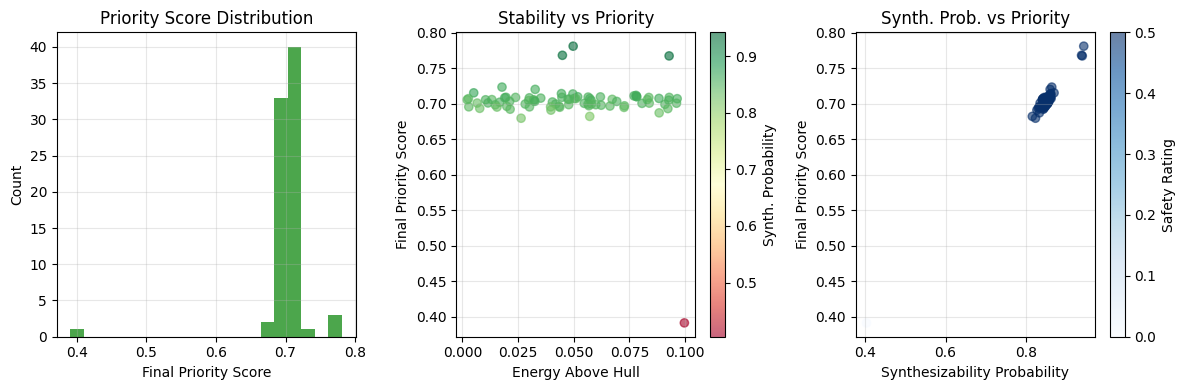

In [46]:
# Calculate synthesis priority ranking (safety-first aware)
print("\n=== SYNTHESIS PRIORITY RANKING ===")

if 'priority_results' not in globals():
    priority_results = calculate_synthesis_priority(synthesis_results).copy()

# Ensure ranking score exists
if 'synthesis_priority_score' not in priority_results.columns:
    base_priority = calculate_synthesis_priority(priority_results)
    priority_results['synthesis_priority_score'] = base_priority['synthesis_priority_score']

# Blend in composite safety-confidence score when available
if 'composite_priority_score' in priority_results.columns:
    priority_results['final_priority_score'] = (
        0.6 * priority_results['synthesis_priority_score'] +
        0.4 * priority_results['composite_priority_score']
    )
else:
    priority_results['final_priority_score'] = priority_results['synthesis_priority_score']

priority_results = priority_results.sort_values('final_priority_score', ascending=False).reset_index(drop=True)
priority_results['synthesis_priority_rank'] = np.arange(1, len(priority_results) + 1)

# Show top 10 materials by final priority
top_candidates = priority_results.head(10)[[
    c for c in [
        'formula', 'final_priority_score', 'synthesis_priority_rank',
        'ensemble_probability', 'ensemble_confidence', 'safety_rating',
        'safety_check_passed', 'energy_above_hull', 'density', 'melting_point'
    ] if c in priority_results.columns
]]

print("Top 10 synthesis candidates (confidence + safety prioritized):")
print(top_candidates.to_string(index=False))

# Summary statistics
print("\nPriority score statistics:")
print(f"- Mean final priority score: {priority_results['final_priority_score'].mean():.3f}")
print(f"- Max final priority score: {priority_results['final_priority_score'].max():.3f}")
if 'safety_check_passed' in priority_results.columns:
    print(f"- Safety-passed materials: {priority_results['safety_check_passed'].sum()}/{len(priority_results)}")
print(f"- Materials with priority > 0.7: {(priority_results['final_priority_score'] > 0.7).sum()}")

# Distribution analysis
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(priority_results['final_priority_score'], bins=20, alpha=0.7, color='green')
plt.xlabel('Final Priority Score')
plt.ylabel('Count')
plt.title('Priority Score Distribution')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.scatter(priority_results['energy_above_hull'], priority_results['final_priority_score'],
           alpha=0.6, c=priority_results['ensemble_probability'], cmap='RdYlGn')
plt.xlabel('Energy Above Hull')
plt.ylabel('Final Priority Score')
plt.title('Stability vs Priority')
plt.colorbar(label='Synth. Probability')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
color_col = 'safety_rating' if 'safety_rating' in priority_results.columns else 'ensemble_confidence'
plt.scatter(priority_results['ensemble_probability'], priority_results['final_priority_score'],
           alpha=0.6, c=priority_results[color_col], cmap='Blues')
plt.xlabel('Synthesizability Probability')
plt.ylabel('Final Priority Score')
plt.title('Synth. Prob. vs Priority')
plt.colorbar(label='Safety Rating' if color_col == 'safety_rating' else 'Confidence')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('synthesis_priority_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [47]:
# Generate synthesis precursor recommendations
print("\n=== SYNTHESIS PRECURSOR RECOMMENDATIONS ===")

# Use filtered final pool when available
final_pool = globals().get('final_candidate_pool')
if final_pool is not None and len(final_pool) > 0:
    top_5_candidates = final_pool.head(5).copy()
else:
    top_5_candidates = priority_results.head(5).copy()

print("Synthesis recommendations for top 5 candidates:")
print("=" * 60)

for i, (_, candidate) in enumerate(top_5_candidates.iterrows(), 1):
    print(f"\nCandidate {i}: {candidate['formula']}")
    print(f"Priority Score: {candidate['synthesis_priority_score']:.3f}")
    print(f"Synthesizability: {candidate['ensemble_probability']:.3f}")
    print(f"Stability (E_hull): {candidate['energy_above_hull']:.3f}")
    
    # Get precursor recommendations
    precursors = generate_precursor_recommendations(candidate.to_dict())
    
    print("Recommended synthesis methods:")
    for j, method in enumerate(precursors, 1):
        print(f"  {j}. {method['method']} ({method['difficulty']})")
        print(f"     Precursors: {', '.join(method['precursors'])}")
        print(f"     Conditions: {method['temperature_range']}")
        print(f"     Success probability: {method['success_probability']:.1f}")
        if j < len(precursors):
            print()


=== SYNTHESIS PRECURSOR RECOMMENDATIONS ===
Synthesis recommendations for top 5 candidates:

Candidate 1: Mn0.554Cu0.446
Priority Score: 0.763
Synthesizability: 0.953
Stability (E_hull): 0.042
Recommended synthesis methods:
  1. Solid State Reaction (Medium)
     Precursors: Elemental powders, Binary oxides
     Conditions: 800-1200°C
     Success probability: 0.8

  2. Arc Melting (Low)
     Precursors: Pure elements, Master alloy
     Conditions: High temperature
     Success probability: 0.9

  3. Chemical Vapor Deposition (High)
     Precursors: Metal halides, Hydrogen, Inert gas
     Conditions: 600-1000°C
     Success probability: 0.6

Candidate 2: Ni0.835Zn0.165
Priority Score: 0.747
Synthesizability: 0.955
Stability (E_hull): 0.081
Recommended synthesis methods:
  1. Solid State Reaction (Medium)
     Precursors: Elemental powders, Binary oxides
     Conditions: 800-1200°C
     Success probability: 0.8

  2. Chemical Vapor Deposition (High)
     Precursors: Metal halides, Hydr


=== COST-BENEFIT ANALYSIS ===
Cost-benefit analysis for top 5 candidates:
       formula recommended_method  success_probability  total_cost  expected_cost  expected_value  net_benefit  benefit_cost_ratio
Mn0.554Cu0.446        arc_melting                 0.90         508         564.44         7689.34      7124.89               13.62
Ni0.835Zn0.165        solid_state                 0.80        1148        1435.00         6276.89      4841.89                4.37
Co0.735Al0.265        solid_state                 0.80        1148        1435.00         6023.83      4588.83                4.20
 V0.569Al0.431        solid_state                 0.80        1148        1435.00         6157.94      4722.94                4.29
 Co0.616V0.384        arc_melting                 0.86         508         590.93         3079.19      2488.26                5.21

Summary:
- Candidates with positive net benefit: 5/5
- Average expected cost: $1092
- Average expected value: $5845
- Average net benefit:

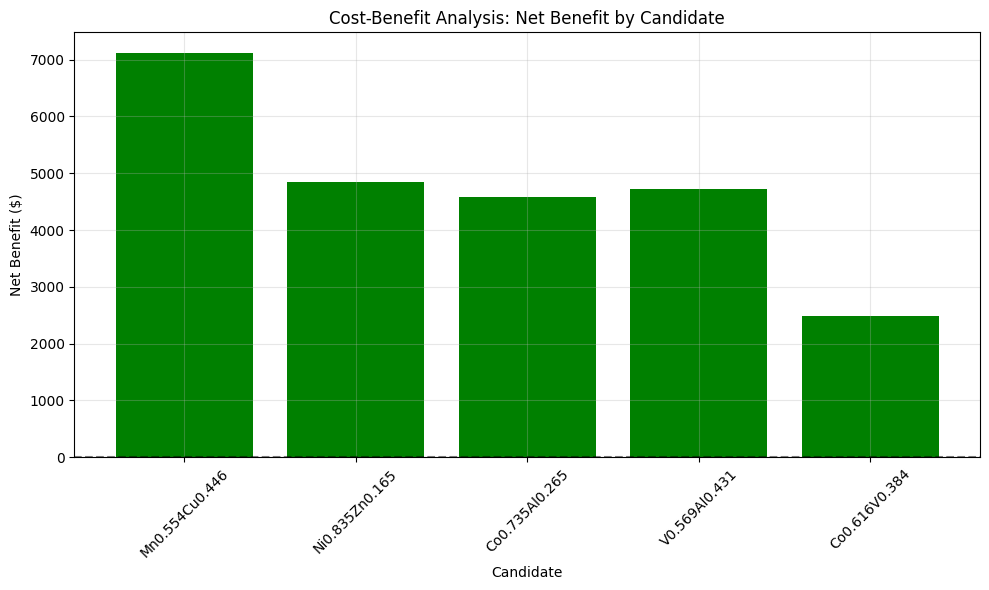

In [48]:
# Perform cost-benefit analysis
print("\n=== COST-BENEFIT ANALYSIS ===")

# Analyze costs and benefits for top candidates
cba_results = []

for _, candidate in top_5_candidates.iterrows():
    cba = cost_benefit_analysis(candidate.to_dict())
    cba['formula'] = candidate['formula']
    cba['priority_score'] = candidate['synthesis_priority_score']
    cba_results.append(cba)

# Display results in a table
cba_df = pd.DataFrame(cba_results)
cba_display = cba_df[['formula', 'recommended_method', 'success_probability', 
                      'total_cost', 'expected_cost', 'expected_value', 'net_benefit', 'benefit_cost_ratio']].copy()

print("Cost-benefit analysis for top 5 candidates:")
print(cba_display.to_string(index=False, float_format='%.2f'))

# Summary statistics
profitable_candidates = cba_df[cba_df['net_benefit'] > 0]
print("\nSummary:")
print(f"- Candidates with positive net benefit: {len(profitable_candidates)}/{len(cba_df)}")
print(f"- Average expected cost: ${cba_df['expected_cost'].mean():.0f}")
print(f"- Average expected value: ${cba_df['expected_value'].mean():.0f}")
print(f"- Average net benefit: ${cba_df['net_benefit'].mean():.0f}")

# Build final candidate pool using confidence + cost efficiency thresholds
confidence_threshold = 0.60
minimum_candidates = 10

top_pool = priority_results.copy()
top_pool = top_pool[top_pool['ensemble_confidence'] >= confidence_threshold].copy()

net_benefit_by_formula = cba_df.set_index('formula')['net_benefit'].to_dict()
top_pool['estimated_net_benefit'] = top_pool['formula'].map(net_benefit_by_formula)

efficient_pool = top_pool[top_pool['estimated_net_benefit'].fillna(0) > 0].copy()
if len(efficient_pool) >= minimum_candidates:
    final_candidate_pool = efficient_pool
else:
    # Relax cost filter but preserve confidence floor, then top-up by priority if still needed
    final_candidate_pool = top_pool.copy()
    if len(final_candidate_pool) < minimum_candidates:
        top_up = priority_results[~priority_results['formula'].isin(final_candidate_pool['formula'])].head(minimum_candidates - len(final_candidate_pool))
        final_candidate_pool = pd.concat([final_candidate_pool, top_up], ignore_index=True)

final_candidate_pool = final_candidate_pool.sort_values('final_priority_score', ascending=False).reset_index(drop=True)

print(f"\n🎯 Final candidate pool: {len(final_candidate_pool)} materials")
print(f"- Confidence threshold: {confidence_threshold:.2f}")
print(f"- Cost filter strict pass count: {len(efficient_pool)}")

# Visualization
plt.figure(figsize=(10, 6))
bars = plt.bar(range(len(cba_df)), cba_df['net_benefit'], 
               color=['green' if x > 0 else 'red' for x in cba_df['net_benefit']])
plt.xlabel('Candidate')
plt.ylabel('Net Benefit ($)')
plt.title('Cost-Benefit Analysis: Net Benefit by Candidate')
plt.xticks(range(len(cba_df)), cba_df['formula'], rotation=45)
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('cost_benefit_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [49]:
# Export NOME intake package (CSV + manifest + NOME-compatible XLSX)
import json
from datetime import datetime, timezone
import pymatgen.core as mg

if 'final_candidate_pool' in globals() and len(final_candidate_pool) > 0:
    candidate_df = final_candidate_pool.copy()
elif 'priority_results' in globals() and len(priority_results) > 0:
    candidate_df = priority_results.copy()
else:
    raise RuntimeError(
        "No candidate table available yet. Run ranking/filtering cells first "
        "(through cost-benefit and final candidate pool creation)."
    )

# Keep a compact schema for NOME-side ingestion
nome_columns = [
    'formula', 'element_1', 'element_2', 'element_3',
    'composition_1', 'composition_2', 'composition_3',
    'ensemble_probability', 'ensemble_confidence',
    'safety_rating', 'safety_check_passed', 'requires_human_override',
    'final_priority_score', 'estimated_net_benefit', 'energy_above_hull', 'band_gap', 'density'
]

for col in nome_columns:
    if col not in candidate_df.columns:
        candidate_df[col] = np.nan

candidate_df = candidate_df[nome_columns].copy().head(100)

# Spreadsheet formula injection hardening for any text cells exported to CSV/XLSX
def _neutralize_spreadsheet_formula(value):
    if isinstance(value, str):
        stripped = value.lstrip()
        if stripped.startswith(('=', '+', '-', '@')):
            return "'" + value
    return value

for col in candidate_df.columns:
    if candidate_df[col].dtype == object:
        candidate_df[col] = candidate_df[col].apply(_neutralize_spreadsheet_formula)

nome_dir = 'nome-software'
csv_path = f'{nome_dir}/generated_materials_for_nome_validation.csv'
manifest_path = f'{nome_dir}/generated_materials_for_nome_validation_manifest.json'
xlsx_path = f'{nome_dir}/generated_materials_for_nome_validation_elem_data.xlsx'

candidate_df.to_csv(csv_path, index=False)

manifest = {
    'exported_at_utc': datetime.now(timezone.utc).isoformat(),
    'source_notebook': 'materials_discovery_workshop_colab_real_data.ipynb',
    'data_source_mode': globals().get('data_type', 'unknown'),
    'candidate_count': int(len(candidate_df)),
    'columns': list(candidate_df.columns),
    'confidence_threshold': 0.60,
    'notes': [
        'Generated candidates are computationally screened only.',
        'NOME workflows typically require experimental/measurement context for full validation.',
        'BCF files are instrument outputs and are not generated by this notebook.',
        'An Excel elements workbook is exported for NOME composition intake.'
    ]
}

with open(manifest_path, 'w', encoding='utf-8') as f:
    json.dump(manifest, f, indent=2)

# Build NOME-compatible elemental composition workbook
element_weights = {}
for _, row in candidate_df.iterrows():
    for elem_col, comp_col in [('element_1', 'composition_1'), ('element_2', 'composition_2'), ('element_3', 'composition_3')]:
        elem = row.get(elem_col)
        comp = row.get(comp_col)
        if pd.notna(elem) and pd.notna(comp):
            element_weights[elem] = element_weights.get(elem, 0.0) + float(comp)

if element_weights:
    total_weight = sum(element_weights.values())
    elements_rows = []
    for element, value in sorted(element_weights.items(), key=lambda x: x[1], reverse=True):
        atomic_percent = (value / total_weight) * 100.0 if total_weight > 0 else 0.0

        # NOME currently uses column 0 (element symbol) and column 4 (atomic percent).
        # Keep intermediate metadata columns stable and best-effort populated.
        try:
            atomic_number = int(mg.Element(element).Z)
        except Exception:
            atomic_number = np.nan

        try:
            atomic_mass = float(mg.Element(element).atomic_mass)
        except Exception:
            atomic_mass = np.nan

        density_g_cm3 = np.nan

        elements_rows.append({
            'element': _neutralize_spreadsheet_formula(element),
            'atomic_number': atomic_number,
            'atomic_mass': atomic_mass,
            'density_g_cm3': density_g_cm3,
            'atomic_percent': atomic_percent
        })

    elements_df = pd.DataFrame(elements_rows)

    # RIS_analysis reads sheet 'elements' and indexes col0 for element and col4 for atomic %.
    elements_df = elements_df[['element', 'atomic_number', 'atomic_mass', 'density_g_cm3', 'atomic_percent']]

    try:
        with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
            elements_df.to_excel(writer, sheet_name='elements', index=False)
        xlsx_exported = True
    except Exception as e:
        xlsx_exported = False
        print(f"⚠️ Could not write XLSX file ({xlsx_path}): {e}")
        print("Install openpyxl in the active environment to enable XLSX export.")
else:
    xlsx_exported = False
    print("⚠️ No elemental composition data available to build NOME XLSX workbook.")

print('✅ NOME intake package exported')
print(f'CSV: {csv_path}')
print(f'Manifest: {manifest_path}')
if xlsx_exported:
    print(f'NOME XLSX (elements sheet): {xlsx_path}')
print(f'Rows: {len(candidate_df)}')

✅ NOME intake package exported
CSV: nome-software/generated_materials_for_nome_validation.csv
Manifest: nome-software/generated_materials_for_nome_validation_manifest.json
NOME XLSX (elements sheet): nome-software/generated_materials_for_nome_validation_elem_data.xlsx
Rows: 79


## Step 7: Export NOME Intake Package

This step writes a NOME intake package from the filtered candidate pool:
- `generated_materials_for_nome_validation.csv`
- `generated_materials_for_nome_validation_manifest.json`
- `generated_materials_for_nome_validation_elem_data.xlsx` (sheet: `elements`)

Use this package in the NOME notebook precheck cell before EDX map workflows.

Note: `.bcf` files are microscope/instrument outputs and are not generated by this notebook.

In [50]:
# Create experimental validation workflow
print("\n=== EXPERIMENTAL VALIDATION WORKFLOW ===")

workflow_input = final_candidate_pool if 'final_candidate_pool' in globals() and len(final_candidate_pool) > 0 else priority_results

# Create prioritized workflow for top materials
experimental_workflow = create_experimental_workflow(workflow_input, top_n=10)

print("Prioritized experimental validation workflow:")
print("=" * 60)
print(experimental_workflow.to_string(index=False))

# Workflow summary
print("\nWorkflow Summary:")
print(f"- Total materials in workflow: {len(experimental_workflow)}")
print(f"- Batches: {experimental_workflow['batch_number'].max()}")
print(f"- High priority materials: {len(experimental_workflow[experimental_workflow['priority_level'] == 'High'])}")
print(f"- Medium priority materials: {len(experimental_workflow[experimental_workflow['priority_level'] == 'Medium'])}")
print(f"- Low priority materials: {len(experimental_workflow[experimental_workflow['priority_level'] == 'Low'])}")

# Time estimate
total_time = experimental_workflow['estimated_time_days'].sum()
print(f"- Estimated total time: {total_time:.1f} days")
print(f"- Average time per material: {experimental_workflow['estimated_time_days'].mean():.1f} days")

# Export workflow
experimental_workflow.to_csv('experimental_workflow.csv', index=False)
print("\nWorkflow exported to 'experimental_workflow.csv'")

# Final recommendations
print("\n=== FINAL SYNTHESIZABILITY VALIDATION SUMMARY ===")
print("🧪 SYNTHESIZABILITY WORKSHOP COMPLETED! 🧪")
print("=" * 60)
print(f"Started with: {len(generated_df)} ML-generated materials")
print(f"Thermodynamically stable: {len(stable_materials)} ({len(stable_materials)/len(generated_df)*100:.1f}%)")
print(f"Predicted synthesizable: {synthesis_results['ensemble_prediction'].sum()} ({synthesis_results['ensemble_prediction'].mean()*100:.1f}%)")
print(f"High-priority candidates: {len(workflow_input.head(10))} materials prioritized for synthesis")
print(f"Positive ROI candidates: {len(profitable_candidates)} materials with net benefit > $0")
print("\n📋 EXPERIMENTAL WORKFLOW READY")
print("Next steps:")
print("1. Begin synthesis with high-priority candidates")
print("2. Validate predictions experimentally")
print("3. Update ML models with new experimental data")
print("4. Scale up production-ready materials")

print("\n🚀 This completes the end-to-end materials discovery pipeline!")
print("From data to lab synthesis - accelerated by machine learning.")


=== EXPERIMENTAL VALIDATION WORKFLOW ===
Prioritized experimental validation workflow:
 workflow_step  batch_number priority_level  synthesis_priority_score  synthesizability_probability  energy_above_hull  formation_energy_per_atom  estimated_time_days required_equipment
             1             1           High                  0.752123                      0.917333           0.049716                   0.018092                  3.5 Arc Melter/Furnace
             2             1           High                  0.735375                      0.909583           0.044885                   0.089812                  6.9 Arc Melter/Furnace
             3             1           High                  0.732449                      0.912083           0.092787                   0.069699                 13.3 Arc Melter/Furnace
             4             1         Medium                  0.724608                      0.804250           0.017777                   0.402991                 10.0 A

## 🎉 Workshop Summary

Congratulations! You've successfully completed the Materials Discovery Workshop with real data integration and synthesizability validation.

In [51]:
# Workshop summary
print("🎊 MATERIALS DISCOVERY WORKSHOP COMPLETED! 🎊")
print("=" * 60)

print(f"📊 Data Source: {data_type.upper()}")
print(f"📚 Training Materials: {len(ml_features)}")
print(f"🎨 Generated Materials: {len(generated_df)}")
print(f"🧠 VAE Latent Dimension: {model.latent_dim}")
print(f"📈 Training Epochs: {params['epochs']}")

print("\n✅ Key Achievements:")
if data_type == 'real':
    print("  • Integrated real Materials Project data")
    print("  • Trained ML model on verified materials")
    print("  • Generated potentially synthesizable materials")
    print("  • Connected to production materials database")
else:
    print("  • Mastered VAE for materials generation")
    print("  • Learned ML concepts with synthetic data")
    print("  • Explored materials property relationships")
    print("  • Set up foundation for real data integration")

print("\n🚀 Next Steps:")
print("  • Experiment with different VAE architectures")
print("  • Try Materials Project data for production use")
print("  • Validate generated materials experimentally")
print("  • Explore reinforcement learning for property optimization")

print("\n🔬 Science Impact:")
print("  • Accelerated materials discovery workflow")
print("  • AI-assisted alloy design")
print("  • Integration of ML with materials databases")
print("  • Foundation for autonomous materials R&D")

print("\n💡 Remember: The future of materials science is AI-augmented! 🚀")

🎊 MATERIALS DISCOVERY WORKSHOP COMPLETED! 🎊
📊 Data Source: REAL
📚 Training Materials: 556
🎨 Generated Materials: 500
🧠 VAE Latent Dimension: 5
📈 Training Epochs: 200

✅ Key Achievements:
  • Integrated real Materials Project data
  • Trained ML model on verified materials
  • Generated potentially synthesizable materials
  • Connected to production materials database

🚀 Next Steps:
  • Experiment with different VAE architectures
  • Try Materials Project data for production use
  • Validate generated materials experimentally
  • Explore reinforcement learning for property optimization

🔬 Science Impact:
  • Accelerated materials discovery workflow
  • AI-assisted alloy design
  • Integration of ML with materials databases
  • Foundation for autonomous materials R&D

💡 Remember: The future of materials science is AI-augmented! 🚀
